# E59: Does a readout trained only on Pile text find the half-known values before the last block?

## The answer

We could not tell. We trained one linear readout per block on ordinary Pile text. The aim was a label for the half-known values that uses neither the decomposition nor the model's output. The readouts memorised their training text and did not even reproduce the model's own ranks at the last block, so the test failed its own construction check. No block held the cipher's values, but a readout this weak would miss them anyway. The "half-known" label still rests on the model's output alone.

## What we were trying to test

The project asks whether a VPD decomposition can tell a fine-tune that strengthens something the original model already does from one that teaches it something new. An earlier experiment built a pair for this on the 67M model. Each window is Pile text with a rare marker token, then a key word, and the model must predict the key's value next. Both tasks use the same 32 keys.

- **Elicit map.** Each key's value is a word the original model's averaged prediction after the key already ranks 2nd to 20th.
- **Cipher.** The same keys mapped to words the original model almost never predicts there.

The decomposition separates the two. Let only Γ, the causal-importance function, see the fine-tuned activations, with every subcomponent's weights kept at their original values. That recovers about three quarters of the elicit map's gain and about a quarter of the cipher's. But the label "half-known" was read off the model's own output ranks. A sceptic can say the pair was built to make the decomposition read high.

This experiment looked for a label from outside both. Jain et al. 2024, Definition 1, say a model possesses a capability when a linear readout trained on pretraining data recovers it from the model's activations.

- **Readout.** One linear map per block, from that block's 768-number output to scores over the 50,277-word vocabulary. Each is trained to predict the next token on random Pile windows, never on the task windows, with the paper's schedule of 4,000 optimiser steps.
- **Rank of a value.** At the answer position of the 97 held-out task windows, the value's place in the readout's scores, with 1 the top word. A key's rank is the median over its windows.
- **Possessed at a block.** At least 24 of the 32 keys have median rank 20 or better, the band the elicit pair was built with.
- **Construction check.** At the last block the readout should agree with the model's own output. At least 24 elicit values should sit at rank 2 to 20, and at least 24 cipher values below rank 100. If it fails, the readout is not reading what the model reads, and the run stops.
- **Readout quality.** The last block's loss on unseen Pile text must come within 0.1 nats of a linearised head. That head is the model's own unembedding with the final norm's per-token scale fixed at its mean. It is a linear map the readout could learn, so a readout that cannot match it is badly fitted.

A second half was planned and never reached. On twelve saved fine-tunes it would remove the readout's direction for the target value at the answer position, and read what share of each fine-tune's gain is lost.

## What we expected, and why

- **The elicit values are held before the last block, the cipher's nowhere.** The elicit values are words the model already predicts after the key, so some earlier block should carry them in a direction a Pile-trained readout finds. The cipher's values are words the model never predicts there. If the readout found the elicit values only at the last block, "half-known" would just mean "what the output already says". We leaned medium on this.
- **Removing the readout's direction costs the elicit fine-tune more than the cipher.** That would show the elicit fine-tune's gain runs through what the original model already used. Lean medium.
- **The last block reproduces the construction.** Lean high: at the last block the readout is close to the unembedding, and this was the run's own check.

## Did the readouts learn the Pile, or memorise it?

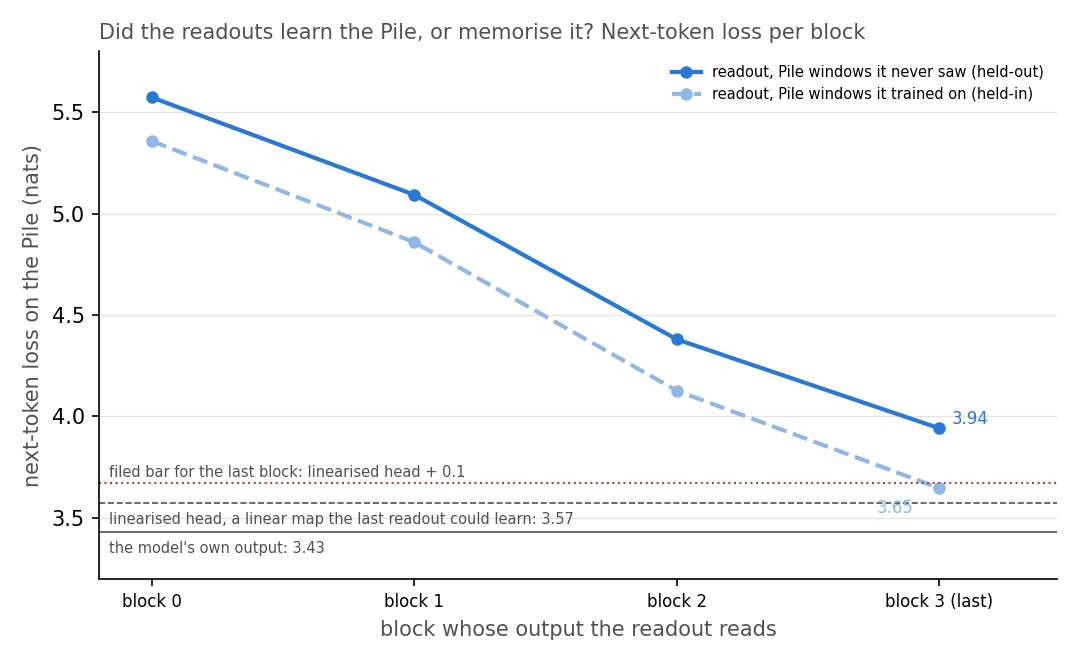

In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/jain_readout/figures")
display(Image(filename=str(FIG / "readout_loss.png")))

**Reading it.** They memorised. On Pile windows it never saw, the last block's readout reached 3.94 nats, 0.37 above the linearised head, against a bar of 0.1. On windows it had trained on, it sat 0.07 above the head, inside the bar. The model and the linearised head read the same on both pools, so the gap belongs to the readout alone. Every block shows it: unseen text reads 0.22 to 0.30 nats worse than seen text.

The cause is the readout's size against its data. Each readout has one row of 768 weights for each of the 50,277 words. A row learns where its word belongs mainly from tokens that have that word as the target. In 15 million training tokens, the rows of rare words see only a handful, so they fit those examples rather than a rule. Jain et al. read a vocabulary of a few hundred, where their schedule never meets this.

### Four jobs, four stops

All four ran on the cluster's free debug queue.

1. **The first job** reused 4.2 million Pile tokens about 3.7 times each. Its last readout scored about 3.2 on its training batches but 4.14 on unseen text, where the model scores 3.43. It overfit, so the training rows were widened until no token was seen more than once in expectation.
2. **The second job** stopped at an early check after 250 steps. The bar there had been set from one noisy batch of the first job, and it was missed by 0.009 nats. The bar was raised, since the check only exists to catch a readout that is not learning at all.
3. **The third job** trained cleanly on fresh rows and missed the quality bar, as in the figure. The gap between seen and unseen text showed this was a sample-size limit, not a bug. Closing it would take four to eight times the tokens, which the free queue's time limit does not allow.
4. **The fourth job** reloaded those saved readouts and read the task windows, with a rule fixed beforehand. A pass would stand, because a weak readout biases against the claim. A miss on the elicit side would read "unreadable". The construction check stayed a stop.

## Does any block's readout hold the elicit values, and none the cipher's?

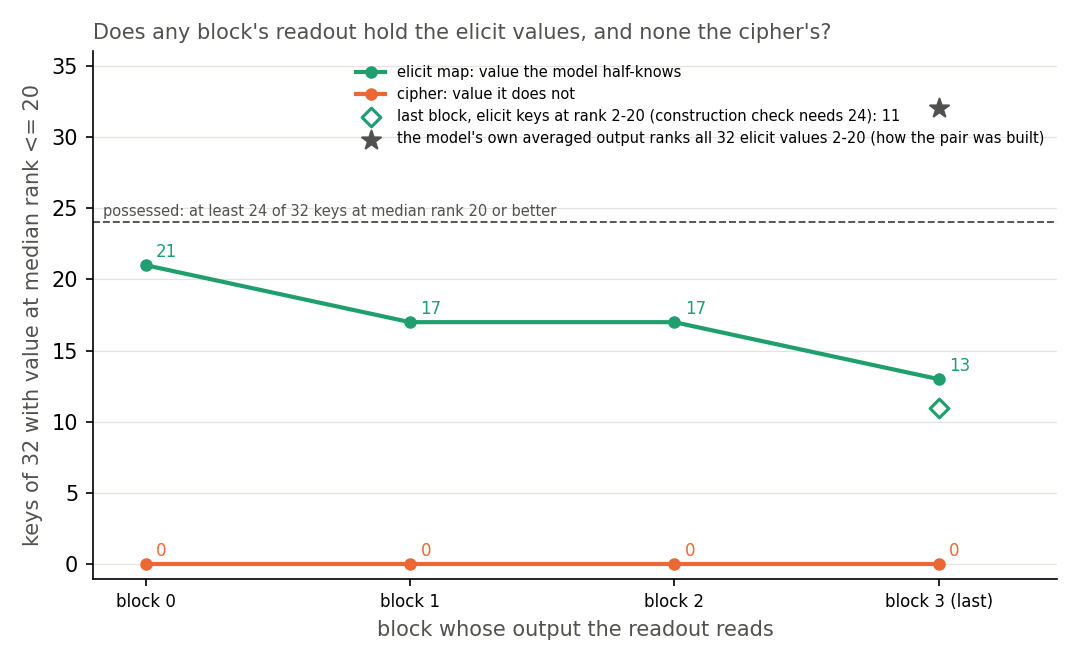

In [2]:
display(Image(filename=str(FIG / "possession.png")))

**Reading it.** No block holds the elicit map, and the last block fails the construction check, so the readout cannot answer the question. The green line counts keys whose value the readout ranks 20th or better. Block 0 comes closest, with 21 keys against the 24 needed. At the last block the readout puts 11 elicit values at rank 2 to 20, where the model's own averaged output puts all 32. That miss stopped the run before the removal tests. The orange line is the cipher: no value reaches rank 20 at any block, and the typical cipher rank is several thousand.

The cipher result bears little weight. A weaker readout ranks every value worse, which pushes towards "not held", the very outcome the cipher side needed. And the cipher's values were chosen as words the model almost never predicts after the key, so any readout that tracks the model even roughly ranks them low. It agrees with the label, but it does not stand apart from the output ranks the label came from.

One odd feature: the elicit count falls with depth, from 21 keys at block 0 to 13 at the last. A readout that tracked the model well would show the opposite near the output. We did not test why. One guess is that the first block's readout acts like a table of likely next words after the key, which is how the elicit values were picked.

## What we learned

The question is still open. A next-token readout over the full vocabulary, trained on 15 million Pile tokens, cannot match the 67M model's own head on unseen text. Nor does it reproduce the model's ranks for the elicit values. So it cannot say whether an earlier block holds them. For `GOALS.md`, the label "strengthens what the model half-knows" still rests on the original model's own output ranks. We have no label for the pair yet that is independent of both VPD and that output. The decomposition's separation of the pair stands as measured, but what it separates is still defined by the output.

## How compelling is the evidence

For the verdict "unreadable", strong: the construction check failed by a wide margin, and the loss gap has a clear cause in the seen-versus-unseen comparison. For anything about the model, weak. The readout is blind to non-linear encodings, and it scores ranks among 50,277 words where the paper scores a few hundred. Each key has about three held-out windows, so a key's median rank is noisy, though the 24-key count absorbs some of that. One key draw, one model, one readout seed.

## Surprises

- The elicit count falls with depth, and the last block holds the fewest elicit values of any block. Unexplained.
- The readouts memorised once-seen tokens, which the first fix, fresh data, was meant to prevent. The vocabulary size, not repetition, was the limit.

## What next

- **A small-vocabulary readout.** Restrict the readout's outputs to the table's values, as Jain et al. do with a few hundred outputs. Each row then sees many examples. If it holds the elicit values at an early block and not the cipher's, the label becomes independent; if only at the last, "half-known" means "what the output says".
- **The same readout on four to eight times the tokens.** One to two hours of an L40 at the measured step time, so the normal queue or a paid card. It needs the user, and the small vocabulary is the cheaper first try.
- **The graded ladder of tables.** Several tables over the same keys at different prior ranks. It keeps a behavioural label, but would show whether the decomposition's reading rises with how well the model knows the value.

## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| stage 0 inputs | saved states and the model's rates reproduce the earlier runs | all twelve states' sha256 and gains exact, difference 0 | pass |
| stage 0 readout loss | last-block held-out loss within 0.1 nats of the linearised head | 3.94 vs 3.57: over by 0.37; held-in over by 0.07 | miss, recorded, not a stop under the amended rule |
| P3 | last block: ≥ 24 elicit keys at rank 2-20, ≥ 24 cipher keys above 100 | elicit 11, cipher 32 | **fail**: the run stopped here |
| P1, elicit clause | elicit possessed at block 0, 1 or 2 | best block 0, 21 of 32 keys; none possessed | unreadable, by the pre-set rule |
| P1, cipher clause | cipher possessed at no block | 0 of 32 keys at every block | holds; little weight |
| P2 | removal of the readout direction costs elicit more than cipher | — | not run |
| do-nothing, W0 control, last-block removal | random direction ≤ 0.05; W0 drops ≥ 0.3 nats | — | not run |

## Departures from the literature

- **Vocabulary.** Jain et al. read a vocabulary of a few hundred; this readout covers all 50,277 words, which is what made it under-fit.
- **Training data and position.** The paper trains the readout on data from the pretraining process and reads it on inputs carrying the task. We train on Pile next-token windows at every position from the second, and read only at the answer position after the marker and key.
- **Threshold.** The paper gives no number for "recovers the capability". Ours, median rank 20 or better for 24 of 32 keys, was filed before the run and matches the band the pair was built with.
- **Quality bar and reading rule.** The linearised-head bar and the rule that an elicit-side miss reads "unreadable" are ours, set after the first and third stops.
- **The causal check** removes the readout direction; the paper prunes neurons or fine-tunes in reverse. It was not reached.
- **Schedule** is the paper's; batch size 96 and the optimiser's defaults were filled in.

## Not run

- The removal tests on the twelve saved fine-tunes, the random-direction control, the original model's control and the last-block removal.
- Readouts on four to eight times the tokens, which need the normal queue or money.
- A small-vocabulary readout restricted to the table's values, closer to Jain et al.
- Reverse fine-tuning, the paper's own causal tool.
- The own-step cipher at seeds 2 to 4, never saved by the earlier run.
- Another key draw, another readout seed, or Qwen.

## Provenance

MATS cluster L40, debug queue, $0. Jobs 48279, 48344, 48357 and 48412; job 48412 reloaded job 48357's readouts. Results `experiments/jain_readout/results/run.json`, earlier versions in its git history; rules and dated amendments in `predictions.json`; figures from `experiments/jain_readout/plot.py`. Full record: `reports/analyses/2026-11-02_analysis_e59-jain-readout.md`.